In [26]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split, RandomizedSearchCV, StratifiedKFold
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    ConfusionMatrixDisplay
)

In [27]:
df=pd.read_csv("/Users/nidagallusandeep/Downloads/credit_default_20000_rows.csv")

In [28]:
df.head()

,customer_id,age,monthly_income,credit_score,debt_to_income_ratio,loan_amount,late_payments,employment_years,dependents,home_ownership,loan_purpose,employment_type,default
0,CR00001,66,41108.32,678.0,0.182,223373.89,0,9.6,1,Mortgage,Business,Unemployed,1
1,CR00002,34,58086.65,653.0,0.288,380649.12,0,5.5,0,Mortgage,Home,Salaried,1
2,CR00003,48,28693.67,586.0,0.095,371543.81,0,4.5,0,Own,Personal,Salaried,1
3,CR00004,41,62796.20,683.0,0.153,212135.12,0,6.2,3,Rent,Education,Salaried,0
4,CR00005,59,38390.94,636.0,0.297,415766.65,4,3.6,1,Own,Personal,Salaried,0


In [29]:
df.shape

(20000, 13)

In [30]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20000 entries, 0 to 19999
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   customer_id           20000 non-null  object 
 1   age                   20000 non-null  int64  
 2   monthly_income        19700 non-null  float64
 3   credit_score          19760 non-null  float64
 4   debt_to_income_ratio  20000 non-null  float64
 5   loan_amount           20000 non-null  float64
 6   late_payments         20000 non-null  int64  
 7   employment_years      20000 non-null  float64
 8   dependents            20000 non-null  int64  
 9   home_ownership        19800 non-null  object 
 10  loan_purpose          20000 non-null  object 
 11  employment_type       19800 non-null  object 
 12  default               20000 non-null  int64  
dtypes: float64(5), int64(4), object(4)
memory usage: 2.0+ MB


In [31]:
df.describe()

,age,monthly_income,credit_score,debt_to_income_ratio,loan_amount,late_payments,employment_years,dependents,default
count,20000.000000,19700.000000,19760.000000,20000.000000,20000.000000,20000.000000,20000.000000,20000.00000,20000.000000
mean,44.109650,52092.216120,674.424899,0.302762,402946.998568,1.296750,6.112030,2.49135,0.262950
std,15.266112,17943.561827,69.484889,0.151796,235927.722997,1.148763,3.770711,1.70809,0.440247
min,18.000000,8000.000000,421.000000,0.010000,5000.000000,0.000000,0.000000,0.00000,0.000000
25%,31.000000,39949.445000,627.000000,0.186000,198883.492500,0.000000,3.300000,1.00000,0.000000
50%,44.000000,52090.950000,674.000000,0.290000,373967.970000,1.000000,6.000000,3.00000,0.000000
75%,57.000000,64121.760000,723.000000,0.408000,593934.077500,2.000000,8.700000,4.00000,1.000000
max,70.000000,133468.230000,850.000000,0.798000,800000.000000,8.000000,25.000000,5.00000,1.000000


In [32]:
df.columns

Index(['customer_id', 'age', 'monthly_income', 'credit_score',
       'debt_to_income_ratio', 'loan_amount', 'late_payments',
       'employment_years', 'dependents', 'home_ownership', 'loan_purpose',
       'employment_type', 'default'],
      dtype='object')

In [33]:
df.size

260000

In [34]:
df.isnull().sum()

customer_id               0
age                       0
monthly_income          300
credit_score            240
debt_to_income_ratio      0
loan_amount               0
late_payments             0
employment_years          0
dependents                0
home_ownership          200
loan_purpose              0
employment_type         200
default                   0
dtype: int64

In [35]:
df["home_ownership"].value_counts()

home_ownership
Rent        7782
Mortgage    7121
Own         4897
Name: count, dtype: int64

In [36]:
df["loan_purpose"].value_counts()

loan_purpose
Medical      3408
Vehicle      3387
Business     3358
Education    3311
Home         3285
Personal     3251
Name: count, dtype: int64

In [37]:
df["employment_type"].value_counts()

employment_type
Salaried         11477
Self-employed     4005
Contract          2330
Unemployed        1988
Name: count, dtype: int64

In [38]:
df["monthly_income"]=df["monthly_income"].fillna(df["monthly_income"].mean())
df["credit_score"]=df["credit_score"].fillna(df["credit_score"].mean())
df["home_ownership"]=df["home_ownership"].fillna(df["home_ownership"].mode()[0])
df["employment_type"]=df["employment_type"].fillna(df["employment_type"].mode()[0])

In [39]:
df.head()

,customer_id,age,monthly_income,credit_score,debt_to_income_ratio,loan_amount,late_payments,employment_years,dependents,home_ownership,loan_purpose,employment_type,default
0,CR00001,66,41108.32,678.0,0.182,223373.89,0,9.6,1,Mortgage,Business,Unemployed,1
1,CR00002,34,58086.65,653.0,0.288,380649.12,0,5.5,0,Mortgage,Home,Salaried,1
2,CR00003,48,28693.67,586.0,0.095,371543.81,0,4.5,0,Own,Personal,Salaried,1
3,CR00004,41,62796.20,683.0,0.153,212135.12,0,6.2,3,Rent,Education,Salaried,0
4,CR00005,59,38390.94,636.0,0.297,415766.65,4,3.6,1,Own,Personal,Salaried,0


In [40]:
df.isnull().sum()

customer_id             0
age                     0
monthly_income          0
credit_score            0
debt_to_income_ratio    0
loan_amount             0
late_payments           0
employment_years        0
dependents              0
home_ownership          0
loan_purpose            0
employment_type         0
default                 0
dtype: int64

In [41]:
df.duplicated().sum()

np.int64(0)

In [42]:
X = df.drop(columns=["customer_id", "default"])
y = df["default"]

In [43]:
numeric_features = [
    "age",
    "monthly_income",
    "credit_score",
    "debt_to_income_ratio",
    "loan_amount",
    "late_payments",
    "employment_years",
    "dependents"]
categorical_features = [
    "home_ownership",
    "loan_purpose",
    "employment_type"]

In [44]:
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.20,random_state=42,stratify=y)
print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)

Training shape: (16000, 11)
Testing shape: (4000, 11)


# Apply Encoding and Scaling

In [45]:
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)])

In [46]:
baseline_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", SVC(
        kernel="rbf",
        probability=True,
        random_state=42))])

baseline_model.fit(X_train, y_train)

/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/sklearn/svm/_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](11,)","['age','monthly_income','credit_score',...,'home_ownership','loan_purpose', 'employment_type']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,11
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numeric', ...), ('categorical', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifyin

In [48]:
y_pred = baseline_model.predict(X_test)
y_prob = baseline_model.predict_proba(X_test)[:, 1]

In [49]:
print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred, zero_division=0))
print("Recall:", recall_score(y_test, y_pred, zero_division=0))
print("F1 Score:", f1_score(y_test, y_pred, zero_division=0))
print("ROC-AUC:", roc_auc_score(y_test, y_prob))

Accuracy: 0.78
Precision: 0.6755102040816326
Recall: 0.314638783269962
F1 Score: 0.4293125810635538
ROC-AUC: 0.7517534604887762


In [50]:
print(classification_report(y_test, y_pred, zero_division=0))

              precision    recall  f1-score   support

           0       0.79      0.95      0.86      2948
           1       0.68      0.31      0.43      1052

    accuracy                           0.78      4000
   macro avg       0.74      0.63      0.65      4000
weighted avg       0.76      0.78      0.75      4000



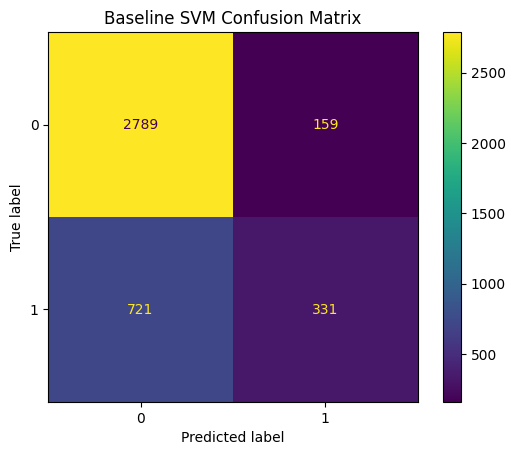

In [51]:
ConfusionMatrixDisplay.from_predictions(y_test,y_pred)
plt.title("Baseline SVM Confusion Matrix")
plt.show()